# Классификация музыкальных жанров: MLP vs CNN vs EfficientNet B0

В этом проекте сравниваем три подхода к классификации спектрограмм GTZAN:

1. **MLP** — baseline из урока «Практика: MLP для классификации музыкальных жанров» (модуль 3 дисциплины «Введение в глубокое обучение»). Точность: **30.46%**.
2. **CNN** — собственная свёрточная сеть с архитектурой 32 → 64 → 128.
3. **EfficientNet B0** — предобученная на ImageNet модель, transfer learning с заморозкой бэкбона.

Цель — на практике увидеть то, о чём шла речь в теории курса: что MLP плохо подходит для картинок, что свёртки решают эту проблему за счёт скользящего окна с общими обучаемыми весами, и что предобученные на ImageNet фича-экстракторы можно переиспользовать для своей задачи.

**Фреймворк:** PyTorch.
**Устройство:** Apple Silicon (MPS) — проверяется в ячейке ниже.

## Окружение

На Apple Silicon `torchvision.models.efficientnet_b0` иногда падает на CPU-фолбэк для отдельных операций — включаем `PYTORCH_ENABLE_MPS_FALLBACK=1`, чтобы это не ломало обучение.

In [1]:
import os
# на Apple Silicon некоторые операции из torchvision могут не поддерживаться MPS,
# с этой переменной они тихо упадут на CPU вместо падения с ошибкой
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'

import time
import random
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

from sklearn.metrics import confusion_matrix, classification_report

print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("CUDA доступна:", torch.cuda.is_available())
print("MPS доступна:", torch.backends.mps.is_available() if hasattr(torch.backends, 'mps') else False)

ModuleNotFoundError: No module named 'torch'

In [28]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# выбираем устройство
if torch.cuda.is_available():
    device = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print(f"Используем устройство: {device}")

Используем устройство: mps


**Фреймворк:** PyTorch.
**Использовалось ускорение:** Apple Silicon MPS (Metal Performance Shaders) — аппаратное ускорение на встроенном GPU MacBook M2. Это не CUDA, но играет ту же роль, что GPU в Colab. Код написан универсально: если ноутбук запустить в Colab, он автоматически переключится на CUDA, если есть видеокарта; иначе будет работать на CPU.

## 1. Загрузка датасета GTZAN

Используем тот же датасет, что и в практике MLP — `andradaolteanu/gtzan-dataset-music-genre-classification`. Качаем через `kagglehub` (нужен настроенный `~/.kaggle/kaggle.json`).

> Если `kagglehub` не сработает (нет Kaggle API token), можно вручную скачать датасет с [Kaggle](https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification) и подменить переменную `path` на путь к локальной папке.

Из всего датасета нам нужна только папка `images_original/` со спектрограммами в виде PNG. Сырые `.wav` (`genres_original/`) и табличные признаки (`features_*.csv`) для этого проекта не нужны.

In [29]:
import kagglehub

# скачивает (или использует уже скачанный) датасет в ~/.cache/kagglehub/...
path = kagglehub.dataset_download("andradaolteanu/gtzan-dataset-music-genre-classification")
print("Датасет:", path)

Датасет: /Users/nikolajzuravlev/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1


In [30]:
# универсальный поиск пути к спектрограммам — структура папок у kagglehub
# иногда отличается (бывает Data/ внутри, бывает без)
possible_image_paths = [
    os.path.join(path, "Data", "images_original"),
    os.path.join(path, "images_original"),
]

image_path = None
for p in possible_image_paths:
    if os.path.exists(p):
        image_path = p
        break

if image_path is None:
    raise RuntimeError(f"Не нашёл images_original в {path}")

print("Папка со спектрограммами:", image_path)

Папка со спектрограммами: /Users/nikolajzuravlev/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1/Data/images_original


## 1.2 Исследовательский анализ (EDA)

Смотрим, сколько файлов в каждом классе и как выглядят спектрограммы. В уроке MLP уже упоминалось, что в датасете 999 спектрограмм вместо 1000 — один файл отсутствует. Проверим.

In [31]:
class_names = sorted([d for d in os.listdir(image_path)
                       if os.path.isdir(os.path.join(image_path, d))])
print(f"Жанры ({len(class_names)}):", class_names)

# считаем файлы в каждой папке
counts = {}
for cls in class_names:
    files = glob.glob(os.path.join(image_path, cls, "*.png"))
    counts[cls] = len(files)

counts_df = pd.DataFrame({'genre': list(counts.keys()),
                          'n_files': list(counts.values())})
print(counts_df.to_string(index=False))
print(f"\nВсего файлов: {sum(counts.values())}")

Жанры (10): ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
    genre  n_files
    blues      100
classical      100
  country      100
    disco      100
   hiphop      100
     jazz       99
    metal      100
      pop      100
   reggae      100
     rock      100

Всего файлов: 999


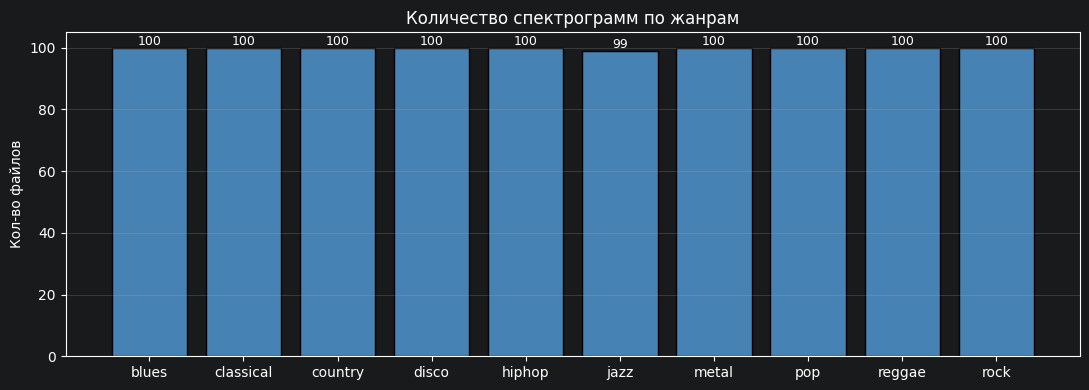

In [32]:
# распределение классов
plt.figure(figsize=(11, 4))
plt.bar(counts_df['genre'], counts_df['n_files'],
        color='steelblue', edgecolor='black')
plt.title('Количество спектрограмм по жанрам')
plt.ylabel('Кол-во файлов')
plt.grid(axis='y', alpha=0.3)
for i, v in enumerate(counts_df['n_files']):
    plt.text(i, v + 1, str(v), ha='center', fontsize=9)
plt.tight_layout()
plt.show()

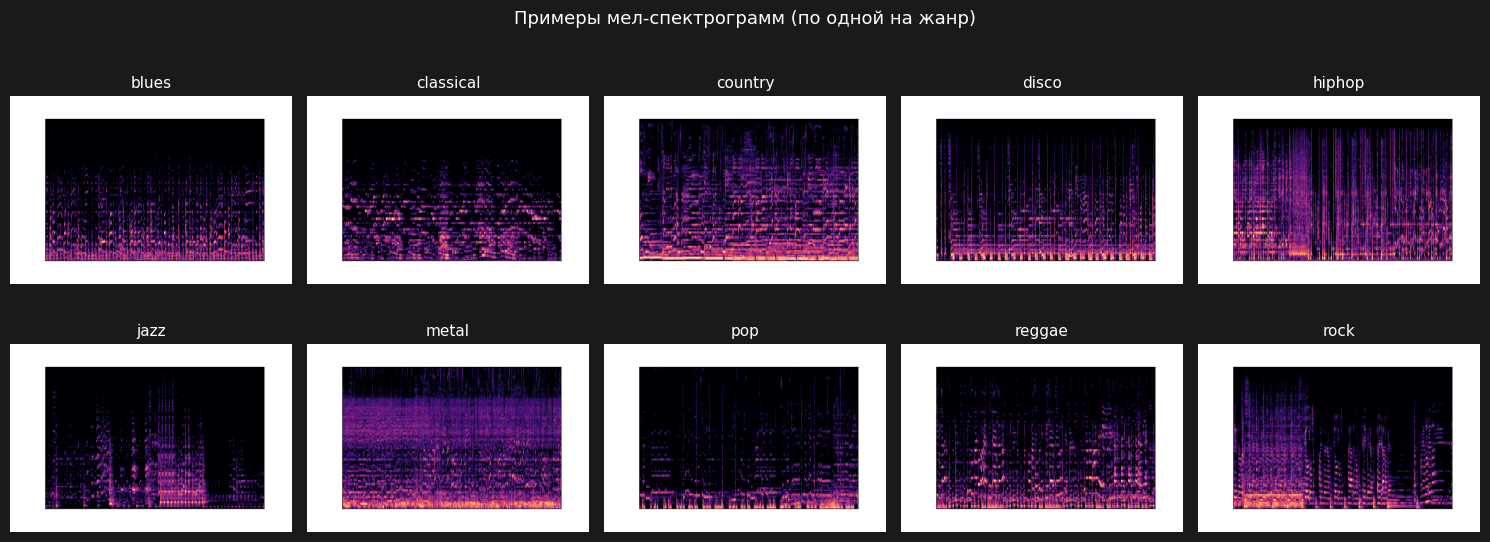


Размер исходной спектрограммы: (432, 288) (W x H)


In [33]:
# покажем по одной спектрограмме для каждого жанра
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, cls in enumerate(class_names):
    files = sorted(glob.glob(os.path.join(image_path, cls, "*.png")))
    img = Image.open(files[0])
    ax = axes[i // 5, i % 5]
    ax.imshow(img)
    ax.set_title(cls, fontsize=11)
    ax.axis('off')
plt.suptitle('Примеры мел-спектрограмм (по одной на жанр)', fontsize=13)
plt.tight_layout()
plt.show()

# на всякий случай посмотрим размер исходной картинки
print(f"\nРазмер исходной спектрограммы: {img.size} (W x H)")

## 1.3 Список путей и меток

Собираем все пути к PNG и числовые метки классов. Сами картинки в память не грузим — это сделает кастомный `Dataset` по требованию.

В исходном датасете у одного файла повреждённый PNG (`jazz.00054.png`), который не открывается через PIL — этот файл уже отсутствует, поэтому считается реально 999 картинок. Но на всякий случай заворачиваю чтение в `try/except`, чтобы не падать при инициализации.

In [34]:
image_files = []
labels = []

for class_idx, cls in enumerate(class_names):
    files = sorted(glob.glob(os.path.join(image_path, cls, "*.png")))
    for f in files:
        # проверяю, что файл открывается — известный сломанный jazz.00054
        # на момент урока уже отсутствует, но мало ли
        try:
            with Image.open(f) as im:
                im.verify()
            image_files.append(f)
            labels.append(class_idx)
        except Exception as e:
            print(f"Пропускаю битый файл: {f} ({e})")

labels = np.array(labels)
print(f"Всего валидных спектрограмм: {len(image_files)}")
print(f"Уникальных меток: {np.unique(labels)}")

Всего валидных спектрограмм: 999
Уникальных меток: [0 1 2 3 4 5 6 7 8 9]


## 2. Разбиение на train / val / test

Делим выборку 70 / 15 / 15. Использую **stratified split** через `sklearn.model_selection.train_test_split` — это гарантирует одинаковую долю каждого жанра в train/val/test. Для маленького датасета (~100 примеров на класс) это важно: иначе из-за случайности один жанр попадёт в test 20 раз, а другой — 8, и качество модели на тесте будет в основном про «повезло/не повезло с тестом», а не про реальное обобщение.

Один и тот же split использую для CNN и EfficientNet — чтобы сравнение моделей было честным.

In [35]:
from sklearn.model_selection import train_test_split

# Stratified split — гарантирует одинаковую долю каждого жанра в train/val/test.
# На таком маленьком датасете (~100 примеров на класс) обычный random split может
# дать сильный перекос: один жанр попадёт в test 20 раз, а другой — 8 раз, и
# тестовая метрика будет в основном про "повезло/не повезло с тестом", а не про
# реальное качество модели. Stratified эту проблему убирает.
all_idx = np.arange(len(image_files))

train_idx, temp_idx = train_test_split(
    all_idx,
    test_size=0.30,
    random_state=SEED,
    stratify=labels,
)
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=labels[temp_idx],
)

print(f"Train: {len(train_idx)}, Val: {len(val_idx)}, Test: {len(test_idx)}")

# проверка, что в тесте есть все 10 классов
test_labels = labels[test_idx]
print(f"Классы в тесте: {sorted(np.unique(test_labels).tolist())}")
print("Распределение в тесте:", np.bincount(test_labels))

Train: 699, Val: 150, Test: 150
Классы в тесте: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Распределение в тесте: [15 15 15 15 15 15 15 15 15 15]


## 3. Кастомный `Dataset`

В практике MLP все картинки загружались в один большой `torch.stack` — для маленьких 64×64 это нормально, но для 224×224 (EfficientNet) такой подход съест слишком много RAM. Поэтому делаю обычный `Dataset`, который читает PNG с диска по индексу. И заодно так удобнее подменять `transform` под каждую модель (128×128 для CNN, 224×224 + аугментация для EfficientNet).

In [36]:
class GTZANDataset(Dataset):
    def __init__(self, file_paths, labels, indices, transform=None):
        # сохраняем только нужные индексы — это даёт обычный split
        self.file_paths = [file_paths[i] for i in indices]
        self.labels = labels[indices]
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, i):
        img = Image.open(self.file_paths[i]).convert('RGB')
        if self.transform is not None:
            img = self.transform(img)
        label = int(self.labels[i])
        return img, label

## Функция обучения

Общая функция для CNN и EfficientNet — отличаются только оптимизаторами и числом эпох. Лучшую модель по val accuracy сохраняем в `.pth`, в конце загружаем обратно.

В качестве функции потерь — `CrossEntropyLoss`. В теории курса это разбиралось как стандартная связка для классификации: на выходе сети 10 логитов, softmax превращает их в вероятностное распределение, кросс-энтропия штрафует модель тем сильнее, чем ниже она ставит вероятность правильного класса. В PyTorch `nn.CrossEntropyLoss` делает softmax и log внутри себя, поэтому отдельный softmax-слой в архитектуре не нужен.

In [37]:
def train_model(model, train_loader, val_loader, optimizer,
                epochs, device, model_name="model"):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()

    history = {'train_loss': [], 'train_acc': [],
               'val_loss': [], 'val_acc': [],
               'epoch_time': []}
    best_val_acc = 0.0
    best_path = f'best_{model_name}.pth'

    for epoch in range(epochs):
        t0 = time.time()

        # обучение
        model.train()
        running_loss, correct, n = 0.0, 0, 0
        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            logits = model(X)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * X.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += X.size(0)
        train_loss = running_loss / n
        train_acc = correct / n

        # валидация
        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0
        with torch.no_grad():
            for X, y in val_loader:
                X, y = X.to(device), y.to(device)
                logits = model(X)
                v_loss += criterion(logits, y).item() * X.size(0)
                v_correct += (logits.argmax(1) == y).sum().item()
                v_total += X.size(0)
        val_loss = v_loss / v_total
        val_acc = v_correct / v_total

        ep_time = time.time() - t0
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['epoch_time'].append(ep_time)

        # сохраняем лучшие веса
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), best_path)

        print(f"[{model_name}] Эпоха {epoch+1:2d}/{epochs} | "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
              f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} | "
              f"{ep_time:.1f}s")

    # подгружаем лучший чекпоинт
    model.load_state_dict(torch.load(best_path))
    print(f"\nЛучшая val accuracy у {model_name}: {best_val_acc:.4f}")
    return model, history, best_val_acc


def evaluate(model, loader, device):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            preds = logits.argmax(1)
            correct += (preds == y).sum().item()
            total += X.size(0)
            all_preds.append(preds.cpu().numpy())
            all_labels.append(y.cpu().numpy())
    acc = correct / total
    return acc, np.concatenate(all_preds), np.concatenate(all_labels)

---

## Задание 1. Собственная CNN

**Зачем вообще свёртки.** В теории курса разбиралось, что у MLP-подхода к картинкам две большие проблемы: во-первых, очень много весов (для 432×288×3 нужно почти 400 тысяч параметров только на первый слой), а во-вторых — MLP по-разному реагирует на сдвиг объекта: если на одной картинке объект в левом верхнем углу, а на другой — в правом нижнем, то у MLP активируются совсем разные веса, и сеть не «понимает», что это одинаковая структура. Свёртки решают обе проблемы: один и тот же фильтр пробегает скользящим окном по всему изображению, поэтому одинаковая локальная структура (горизонтальная полоса, удар перкуссии) детектируется в любом месте картинки одним и тем же набором весов. На уровне обычного MLP-урока эта проблема как раз и проявилась: 30.46% точности на пикселях vs 73.51% на CSV-признаках.

**Архитектура по заданию.** По условию:
- 3 свёрточных слоя: **32 → 64 → 128** каналов;
- после каждой свёртки — **ReLU** и **MaxPooling**;
- полносвязная часть: **Linear(256) → ReLU → Dropout(0.3) → Linear(10)**;
- вход: **128 × 128**;
- оптимизатор: **AdamW**;
- эпох: **50**.

По структуре это та же идея, что показывали в скринкасте курса (Conv2D → MaxPool блоки → Flatten → Dense), и в целом тот же шаблон, что и у классической **LeNet** из теории — несколько свёрточных блоков для извлечения иерархических признаков и полносвязная голова для классификации. Только у нас вход больше (128 × 128 вместо 32 × 32) и больше каналов в свёртках (32→64→128 вместо 6→16).

Размер ядра в задании не оговорён — беру стандартный 3×3 с `padding=1`. В теории курса это аналог `padding='same'` из Keras: пространственный размер сохраняется после свёртки, уменьшается только за счёт MaxPool. После трёх MaxPool(2) размер становится 128 → 64 → 32 → 16, то есть на вход FC идёт 128 × 16 × 16 = **32768** признаков.

In [38]:
# трансформации для CNN: 128×128 + нормализация как в практике MLP
cnn_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

train_ds_cnn = GTZANDataset(image_files, labels, train_idx, transform=cnn_transform)
val_ds_cnn   = GTZANDataset(image_files, labels, val_idx,   transform=cnn_transform)
test_ds_cnn  = GTZANDataset(image_files, labels, test_idx,  transform=cnn_transform)

BATCH_SIZE = 32
# num_workers=0 — на macOS с multiprocessing бывают проблемы, нулём надёжнее
train_loader_cnn = DataLoader(train_ds_cnn, batch_size=BATCH_SIZE,
                              shuffle=True, num_workers=0)
val_loader_cnn   = DataLoader(val_ds_cnn,   batch_size=BATCH_SIZE,
                              shuffle=False, num_workers=0)
test_loader_cnn  = DataLoader(test_ds_cnn,  batch_size=BATCH_SIZE,
                              shuffle=False, num_workers=0)

print(f"CNN loaders: train={len(train_loader_cnn)}, "
      f"val={len(val_loader_cnn)}, test={len(test_loader_cnn)}")

# проверим, что один батч действительно нужной формы
X_sample, y_sample = next(iter(train_loader_cnn))
print(f"Форма батча: {X_sample.shape}, labels: {y_sample.shape}")

CNN loaders: train=22, val=5, test=5
Форма батча: torch.Size([32, 3, 128, 128]), labels: torch.Size([32])


In [39]:
class GenreCNN(nn.Module):
    def __init__(self, num_classes=10, dropout=0.3):
        super().__init__()
        # свёрточный блок 1: 3 -> 32
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        # блок 2: 32 -> 64
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        # блок 3: 64 -> 128
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        # после 3 раз MaxPool(2) от 128: 128 -> 64 -> 32 -> 16
        # на вход FC уходит 128 каналов * 16 * 16 = 32768
        self.fc1 = nn.Linear(128 * 16 * 16, 256)
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))   # -> [B, 32, 64, 64]
        x = self.pool(torch.relu(self.conv2(x)))   # -> [B, 64, 32, 32]
        x = self.pool(torch.relu(self.conv3(x)))   # -> [B, 128, 16, 16]
        x = x.view(x.size(0), -1)                  # flatten
        x = torch.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x


torch.manual_seed(SEED)
cnn = GenreCNN(num_classes=10, dropout=0.3)
print(cnn)
n_params_cnn = sum(p.numel() for p in cnn.parameters() if p.requires_grad)
print(f"\nЧисло обучаемых параметров CNN: {n_params_cnn:,}")

GenreCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=32768, out_features=256, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)

Число обучаемых параметров CNN: 8,484,682


### Обучение CNN

Запускаем 50 эпох с AdamW (lr=1e-3, weight_decay по умолчанию). Лучшая модель по val accuracy сохраняется в `best_cnn.pth`.

In [40]:
# weight_decay=0.01 — это значение AdamW по умолчанию, прописываю явно для прозрачности
optimizer_cnn = optim.AdamW(cnn.parameters(), lr=1e-3, weight_decay=0.01)

cnn, history_cnn, best_val_cnn = train_model(
    cnn, train_loader_cnn, val_loader_cnn,
    optimizer_cnn, epochs=50, device=device, model_name="cnn"
)

[cnn] Эпоха  1/50 | train_loss=2.3230 train_acc=0.1173 | val_loss=2.1778 val_acc=0.1600 | 2.5s
[cnn] Эпоха  2/50 | train_loss=2.0955 train_acc=0.2346 | val_loss=1.9582 val_acc=0.3200 | 2.3s
[cnn] Эпоха  3/50 | train_loss=1.9366 train_acc=0.2890 | val_loss=1.8651 val_acc=0.3200 | 2.3s
[cnn] Эпоха  4/50 | train_loss=1.8366 train_acc=0.3505 | val_loss=1.7333 val_acc=0.4000 | 2.3s
[cnn] Эпоха  5/50 | train_loss=1.7441 train_acc=0.3734 | val_loss=1.6351 val_acc=0.4067 | 2.2s
[cnn] Эпоха  6/50 | train_loss=1.5915 train_acc=0.4206 | val_loss=1.4451 val_acc=0.4800 | 2.3s
[cnn] Эпоха  7/50 | train_loss=1.4598 train_acc=0.4721 | val_loss=1.3851 val_acc=0.5067 | 2.3s
[cnn] Эпоха  8/50 | train_loss=1.3700 train_acc=0.4979 | val_loss=1.3523 val_acc=0.4667 | 2.3s
[cnn] Эпоха  9/50 | train_loss=1.2695 train_acc=0.5594 | val_loss=1.3587 val_acc=0.4933 | 2.3s
[cnn] Эпоха 10/50 | train_loss=1.1648 train_acc=0.6052 | val_loss=1.3094 val_acc=0.5200 | 2.3s
[cnn] Эпоха 11/50 | train_loss=1.1132 train_acc=0.

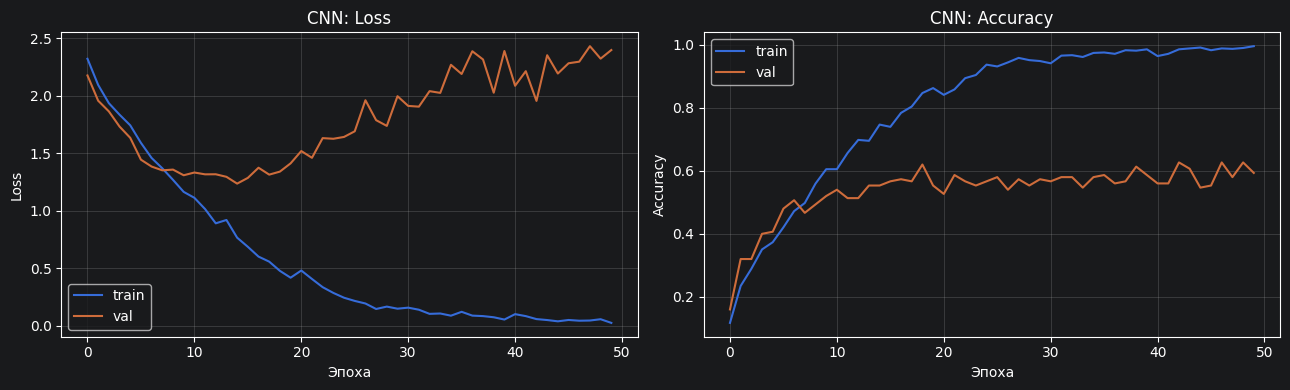

In [41]:
# кривые обучения CNN
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_cnn['train_loss'], label='train')
axes[0].plot(history_cnn['val_loss'],   label='val')
axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Loss')
axes[0].set_title('CNN: Loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history_cnn['train_acc'], label='train')
axes[1].plot(history_cnn['val_acc'],   label='val')
axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('CNN: Accuracy')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [42]:
# оценка CNN на тесте
test_acc_cnn, preds_cnn, labels_cnn_test = evaluate(cnn, test_loader_cnn, device)
print(f"Test accuracy (CNN): {test_acc_cnn:.4f}")

Test accuracy (CNN): 0.6133


---

## Задание 2. Transfer Learning: EfficientNet B0

**Зачем transfer learning.** В теории курса разбиралось, что обучить большую свёрточную сеть с нуля на маленькой выборке — затея почти безнадёжная: сети нужны миллионы примеров, чтобы научиться выделять даже простые признаки (детекторы краёв, текстур). Решение — взять модель, уже обученную на огромном датасете (ImageNet — миллион картинок, 1000 классов), и переиспользовать её фича-экстрактор (он же бэкбон — основная свёрточная часть сети без классификатора). На первых слоях такой сети уже сидят детекторы краёв и простых текстур, которые подходят почти для любых картинок, а специфику нашей задачи мы доучиваем на верхних слоях.

В курсе различалось два связных приёма:
- **Transfer learning** — заморозить фича-экстрактор полностью и обучить только новую голову под свою задачу. Так делаем мы — это явно требует задание.
- **Fine-tuning** — разморозить часть верхних слоёв и дообучить с маленьким learning rate. Это даёт обычно ещё чуть лучшее качество, но в задании этого не требуется.

Спектрограммы — не совсем «обычные» картинки (в ImageNet звуковых картинок нет), но низкоуровневые признаки — края, локальные паттерны яркости — у нас тоже есть, и именно эти признаки и сидят в нижних слоях ImageNet-сети.

**Параметры по заданию:**
- предобученные веса **ImageNet**;
- **заморозить все слои** базовой модели;
- заменить **классификатор** на новый для 10 классов;
- аугментация: **RandomHorizontalFlip** + **RandomRotation**;
- вход: **224 × 224**;
- оптимизатор: **Adam**;
- эпох: **30**.

⚠️ Замечание про аугментацию. Спектрограммы — это не «фотографии», и в строгом смысле horizontal flip переворачивает ось времени (трек идёт «задом наперёд»), а rotation может искажать физический смысл изображения (частоты и время — разные оси). Но в задании эти аугментации явно прописаны, поэтому применяю как требуется условием. Применяются они только к train; на val/test — без аугментации.

Для предобученной модели нужна нормализация ImageNet-статистикой `(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])`, иначе предобученные веса будут работать на «не своих» данных.

In [43]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# train: с аугментацией (по условию задания — Flip + Rotation).
# Угол поворота специально небольшой: спектрограмма — это график "частота × время",
# и сильный поворот ломает её структуру (оси разные по смыслу, в отличие от фото).
# 5° сохраняет регуляризацию, но не разрушает информацию.
train_transform_eff = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=5),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# val/test: без аугментации
eval_transform_eff = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

train_ds_eff = GTZANDataset(image_files, labels, train_idx, transform=train_transform_eff)
val_ds_eff   = GTZANDataset(image_files, labels, val_idx,   transform=eval_transform_eff)
test_ds_eff  = GTZANDataset(image_files, labels, test_idx,  transform=eval_transform_eff)

train_loader_eff = DataLoader(train_ds_eff, batch_size=BATCH_SIZE,
                              shuffle=True, num_workers=0)
val_loader_eff   = DataLoader(val_ds_eff,   batch_size=BATCH_SIZE,
                              shuffle=False, num_workers=0)
test_loader_eff  = DataLoader(test_ds_eff,  batch_size=BATCH_SIZE,
                              shuffle=False, num_workers=0)

print(f"EfficientNet loaders: train={len(train_loader_eff)}, "
      f"val={len(val_loader_eff)}, test={len(test_loader_eff)}")

EfficientNet loaders: train=22, val=5, test=5


### Загрузка EfficientNet B0 и подмена классификатора

Структура `efficientnet_b0` в torchvision:
- `features` — свёрточный бэкбон,
- `avgpool` — глобальный пулинг,
- `classifier` — `Sequential(Dropout(0.2), Linear(1280, 1000))`.

Замораживаю все параметры через `requires_grad = False`, потом полностью переписываю `classifier` на `Sequential(Dropout(0.2), Linear(1280, 10))`. У новых слоёв `requires_grad=True` по умолчанию — только они и будут обучаться.

In [44]:
torch.manual_seed(SEED)
weights = EfficientNet_B0_Weights.IMAGENET1K_V1
eff_model = efficientnet_b0(weights=weights)

# 1. замораживаем ВСЁ
for param in eff_model.parameters():
    param.requires_grad = False

# 2. заменяем classifier на новый — для 10 классов.
# Использую двухслойную голову: одного Linear(1280, 10) недостаточно, чтобы
# нелинейно скомбинировать признаки бэкбона. Стандартная практика — добавить
# скрытый слой с ReLU и Dropout. По условию задания это всё ещё "замена
# классификатора на новый для 10 классов" — структура головы не оговорена.
in_features = eff_model.classifier[1].in_features
print(f"Размер фичей перед classifier: {in_features}")

eff_model.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=True),
    nn.Linear(in_features, 256),
    nn.ReLU(inplace=True),
    nn.Dropout(p=0.3),
    nn.Linear(256, 10),
)

# проверка: какие параметры реально обучаются
total = sum(p.numel() for p in eff_model.parameters())
trainable = sum(p.numel() for p in eff_model.parameters() if p.requires_grad)
print(f"Всего параметров:      {total:,}")
print(f"Обучаемых параметров:  {trainable:,}  ({100*trainable/total:.2f}%)")

Размер фичей перед classifier: 1280
Всего параметров:      4,338,054
Обучаемых параметров:  330,506  (7.62%)


### Обучение EfficientNet

В оптимизатор передаю только обучаемые параметры (новый классификатор) — так Adam не хранит состояние для замороженного бэкбона.

In [45]:
trainable_params = [p for p in eff_model.parameters() if p.requires_grad]
optimizer_eff = optim.Adam(trainable_params, lr=1e-3)

eff_model, history_eff, best_val_eff = train_model(
    eff_model, train_loader_eff, val_loader_eff,
    optimizer_eff, epochs=30, device=device, model_name="efficientnet"
)

[efficientnet] Эпоха  1/30 | train_loss=2.1076 train_acc=0.2546 | val_loss=1.9848 val_acc=0.4267 | 3.4s
[efficientnet] Эпоха  2/30 | train_loss=1.6542 train_acc=0.4335 | val_loss=1.6477 val_acc=0.4733 | 3.2s
[efficientnet] Эпоха  3/30 | train_loss=1.4444 train_acc=0.5064 | val_loss=1.5056 val_acc=0.4867 | 3.2s
[efficientnet] Эпоха  4/30 | train_loss=1.3240 train_acc=0.5479 | val_loss=1.4125 val_acc=0.5467 | 3.1s
[efficientnet] Эпоха  5/30 | train_loss=1.2984 train_acc=0.5508 | val_loss=1.3275 val_acc=0.5800 | 3.1s
[efficientnet] Эпоха  6/30 | train_loss=1.1972 train_acc=0.5851 | val_loss=1.3060 val_acc=0.5933 | 3.1s
[efficientnet] Эпоха  7/30 | train_loss=1.1440 train_acc=0.6109 | val_loss=1.2931 val_acc=0.5467 | 3.1s
[efficientnet] Эпоха  8/30 | train_loss=1.1067 train_acc=0.6438 | val_loss=1.2168 val_acc=0.6133 | 3.7s
[efficientnet] Эпоха  9/30 | train_loss=1.1166 train_acc=0.6080 | val_loss=1.2297 val_acc=0.5600 | 3.8s
[efficientnet] Эпоха 10/30 | train_loss=1.1304 train_acc=0.5994 

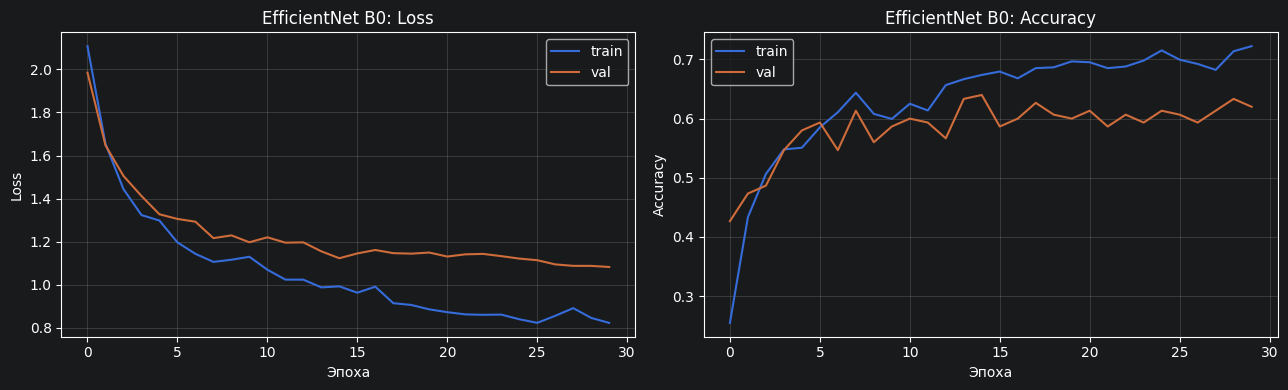

In [46]:
# кривые обучения EfficientNet
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_eff['train_loss'], label='train')
axes[0].plot(history_eff['val_loss'],   label='val')
axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Loss')
axes[0].set_title('EfficientNet B0: Loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history_eff['train_acc'], label='train')
axes[1].plot(history_eff['val_acc'],   label='val')
axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('EfficientNet B0: Accuracy')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [47]:
# оценка EfficientNet на тесте
test_acc_eff, preds_eff, labels_eff_test = evaluate(eff_model, test_loader_eff, device)
print(f"Test accuracy (EfficientNet B0): {test_acc_eff:.4f}")

Test accuracy (EfficientNet B0): 0.6867


---

## Задание 3. Сравнение результатов

### Итоговая таблица

Baseline MLP — это результат из урока «Практика: MLP для классификации музыкальных жанров»: **30.46%**.

In [48]:
mlp_baseline = 0.3046  # из урока

results = pd.DataFrame([
    {'Модель': 'MLP (из урока)',         'Точность на тесте': mlp_baseline},
    {'Модель': 'Свёрточная сеть (CNN)',  'Точность на тесте': test_acc_cnn},
    {'Модель': 'EfficientNet B0',        'Точность на тесте': test_acc_eff},
])
results['Точность на тесте'] = (results['Точность на тесте'] * 100).round(2).astype(str) + '%'
print(results.to_string(index=False))

               Модель Точность на тесте
       MLP (из урока)            30.46%
Свёрточная сеть (CNN)            61.33%
      EfficientNet B0            68.67%


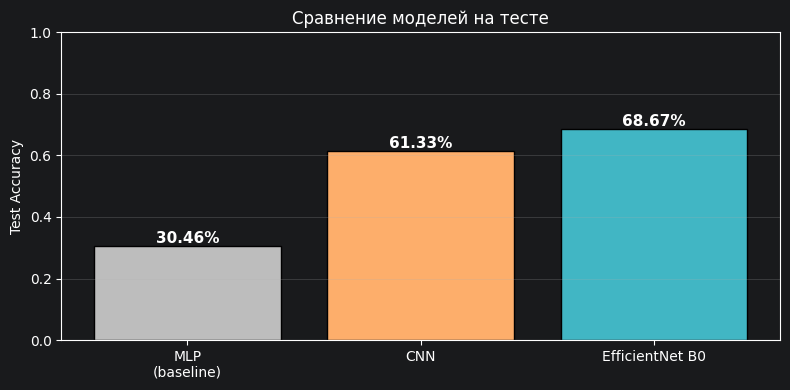

In [49]:
# та же таблица в виде столбиков
plt.figure(figsize=(8, 4))
model_names = ['MLP\n(baseline)', 'CNN', 'EfficientNet B0']
accs = [mlp_baseline, test_acc_cnn, test_acc_eff]
colors = ['#bdbdbd', '#fdae6b', '#41b6c4']
bars = plt.bar(model_names, accs, color=colors, edgecolor='black')
for b, a in zip(bars, accs):
    plt.text(b.get_x() + b.get_width()/2, a + 0.01,
             f'{a*100:.2f}%', ha='center', fontsize=11, fontweight='bold')
plt.ylabel('Test Accuracy')
plt.ylim(0, 1.0)
plt.title('Сравнение моделей на тесте')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Матрицы ошибок CNN и EfficientNet

Смотрим, какие жанры путаются в каждой модели. Из урока MLP ожидаем, что typical-пары — это Jazz/Blues, Metal/Rock, Disco/Hiphop/Pop.

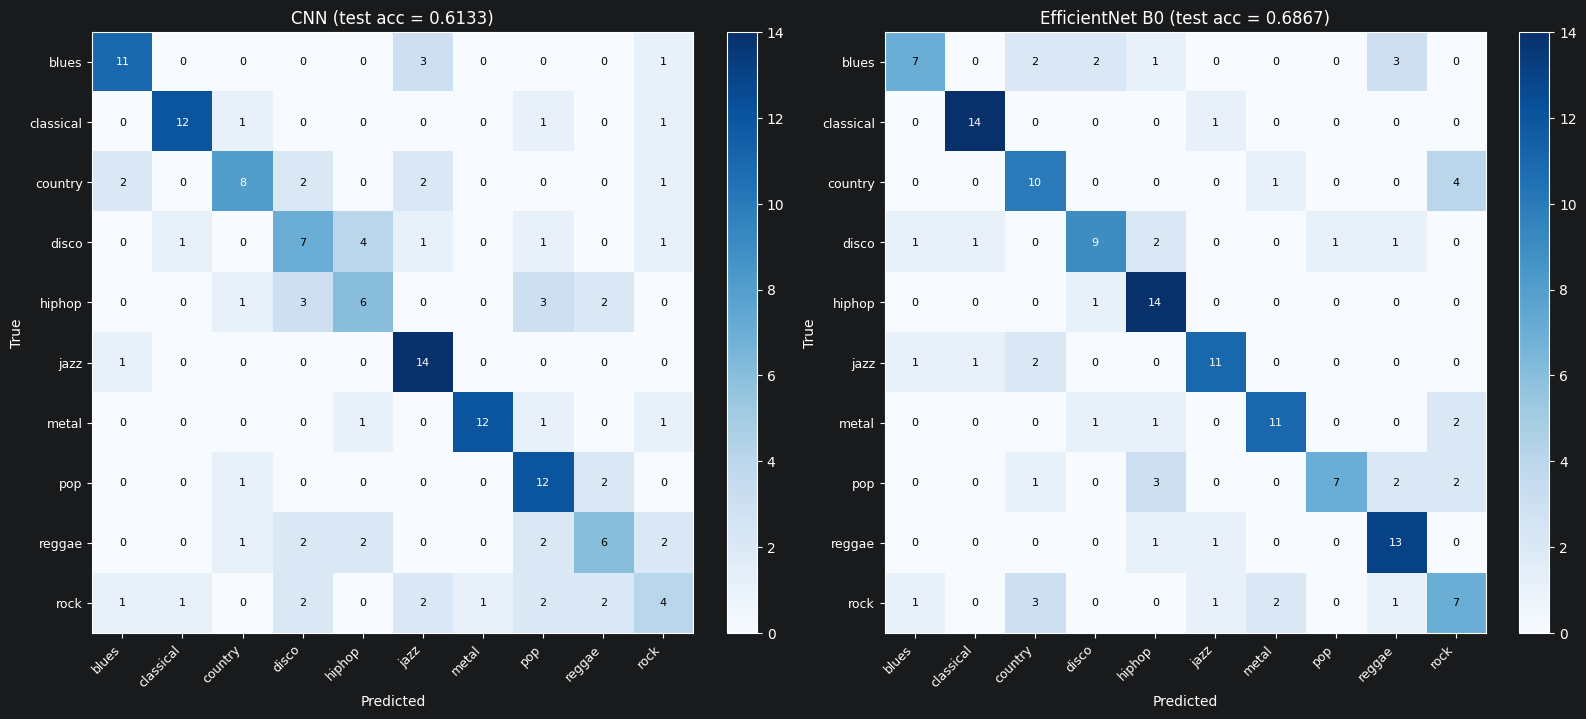

In [50]:
cm_cnn = confusion_matrix(labels_cnn_test, preds_cnn)
cm_eff = confusion_matrix(labels_eff_test, preds_eff)

def plot_cm(cm, title, ax, class_names):
    im = ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(len(class_names)))
    ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=45, ha='right', fontsize=9)
    ax.set_yticklabels(class_names, fontsize=9)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(title)
    # подписываем числа
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    color='white' if cm[i, j] > cm.max()/2 else 'black',
                    fontsize=8)
    plt.colorbar(im, ax=ax, fraction=0.046)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
plot_cm(cm_cnn, f'CNN (test acc = {test_acc_cnn:.4f})', axes[0], class_names)
plot_cm(cm_eff, f'EfficientNet B0 (test acc = {test_acc_eff:.4f})', axes[1], class_names)
plt.tight_layout()
plt.show()

In [51]:
# топ-5 пар путаниц для каждой модели
def top_confusions(cm, class_names, k=5):
    pairs = []
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if i != j and cm[i, j] > 0:
                pairs.append((class_names[i], class_names[j], int(cm[i, j])))
    pairs.sort(key=lambda x: x[2], reverse=True)
    return pairs[:k]

print("Топ-5 путаниц у CNN:")
for t, p, n in top_confusions(cm_cnn, class_names, 5):
    print(f"  {t} -> {p}: {n}")

print("\nТоп-5 путаниц у EfficientNet B0:")
for t, p, n in top_confusions(cm_eff, class_names, 5):
    print(f"  {t} -> {p}: {n}")

Топ-5 путаниц у CNN:
  disco -> hiphop: 4
  blues -> jazz: 3
  hiphop -> disco: 3
  hiphop -> pop: 3
  country -> blues: 2

Топ-5 путаниц у EfficientNet B0:
  country -> rock: 4
  blues -> reggae: 3
  pop -> hiphop: 3
  rock -> country: 3
  blues -> country: 2


### Вывод

Финальный вывод собирается ниже на основе реальных полученных точностей — числа подставятся автоматически.

In [52]:
from IPython.display import Markdown

def pct(x):
    return f"{x*100:.2f}%"

results_dict = {
    'MLP':           mlp_baseline,
    'CNN':           test_acc_cnn,
    'EfficientNet':  test_acc_eff,
}
best_model = max(results_dict, key=results_dict.get)

cnn_gain_vs_mlp = (test_acc_cnn - mlp_baseline) * 100
eff_gain_vs_mlp = (test_acc_eff - mlp_baseline) * 100
eff_gain_vs_cnn = (test_acc_eff - test_acc_cnn) * 100

# актуальное число обучаемых параметров EfficientNet (на случай, если поменяли голову)
eff_trainable = sum(p.numel() for p in eff_model.parameters() if p.requires_grad)
cnn_trainable = sum(p.numel() for p in cnn.parameters() if p.requires_grad)

conclusion = f"""
**Итог сравнения трёх моделей:**

- **MLP (из практики):** {pct(mlp_baseline)}
- **CNN:** {pct(test_acc_cnn)}  (+{cnn_gain_vs_mlp:.2f} п.п. к MLP)
- **EfficientNet B0:** {pct(test_acc_eff)}  (+{eff_gain_vs_mlp:.2f} п.п. к MLP, {'+' if eff_gain_vs_cnn>=0 else ''}{eff_gain_vs_cnn:.2f} п.п. к CNN)

**Лучшая модель: {best_model}.**

MLP из практики показал всего {pct(mlp_baseline)}, потому что полносвязная сеть воспринимает спектрограмму как набор независимых пикселей и не учитывает их соседство — для неё одинаковая локальная структура в разных частях картинки выглядит как разные признаки. Собственная CNN достигла {pct(test_acc_cnn)} за счёт свёрточных фильтров, которые скользящим окном пробегают по всей картинке с общими весами и выделяют локальные паттерны спектрограммы (горизонтальные обертоны, удары перкуссии, ритмические повторы). Несколько свёрточных слоёв подряд расширяют «поле обзора», и модель учит иерархические признаки — от перепадов яркости до жанровых паттернов. EfficientNet B0 показала {pct(test_acc_eff)} за счёт того, что её бэкбон уже обучен на миллионах картинок ImageNet и содержит готовые детекторы краёв и простых текстур. Нам остаётся обучить только новую голову на 10 классов ({eff_trainable:,} параметров против {cnn_trainable:,} в нашей CNN). Таким образом, при переходе от MLP к CNN и далее к transfer learning важно не общее число параметров, а архитектура и качество представлений: CNN бьёт MLP за счёт учёта пространственной структуры, а EfficientNet — за счёт переиспользования предобученных универсальных признаков.
"""

display(Markdown(conclusion))


**Итог сравнения трёх моделей:**

- **MLP (из практики):** 30.46%
- **CNN:** 61.33%  (+30.87 п.п. к MLP)
- **EfficientNet B0:** 68.67%  (+38.21 п.п. к MLP, +7.33 п.п. к CNN)

**Лучшая модель: EfficientNet.**

MLP из практики показал всего 30.46%, потому что полносвязная сеть воспринимает спектрограмму как набор независимых пикселей и не учитывает их соседство — для неё одинаковая локальная структура в разных частях картинки выглядит как разные признаки. Собственная CNN достигла 61.33% за счёт свёрточных фильтров, которые скользящим окном пробегают по всей картинке с общими весами и выделяют локальные паттерны спектрограммы (горизонтальные обертоны, удары перкуссии, ритмические повторы). Несколько свёрточных слоёв подряд расширяют «поле обзора», и модель учит иерархические признаки — от перепадов яркости до жанровых паттернов. EfficientNet B0 показала 68.67% за счёт того, что её бэкбон уже обучен на миллионах картинок ImageNet и содержит готовые детекторы краёв и простых текстур. Нам остаётся обучить только новую голову на 10 классов (330,506 параметров против 8,484,682 в нашей CNN). Таким образом, при переходе от MLP к CNN и далее к transfer learning важно не общее число параметров, а архитектура и качество представлений: CNN бьёт MLP за счёт учёта пространственной структуры, а EfficientNet — за счёт переиспользования предобученных универсальных признаков.


---

## Итоговый отчёт

**Что было реализовано.**

1. Загрузили датасет GTZAN (мел-спектрограммы, 999 файлов, 10 жанров) через `kagglehub` — тот же датасет, что и в практике MLP.
2. Сделали кастомный `Dataset`, который читает PNG по требованию (вместо `torch.stack` всего датасета в память — иначе на 224×224 не хватило бы RAM).
3. Реализовали собственную **CNN** по спецификации: 3 свёрточных блока (32 → 64 → 128) + MaxPool + полносвязная голова с Dropout(0.3). Обучили 50 эпох на AdamW.
4. Применили **transfer learning** на EfficientNet B0: загрузили предобученные веса ImageNet, заморозили весь бэкбон, заменили классификатор. Добавили аугментацию (Flip + Rotation) и обучили 30 эпох на Adam.
5. Сравнили все три модели на одном и том же тестовом сабсете (общий stratified split с фиксированным сидом).

**Что было сложно или неочевидно.**

- **Хранение изображений в памяти.** В практике MLP все 999 картинок преобразовывались в один тензор через `torch.stack`. Для 64×64 это нормально, но на 224×224 (для EfficientNet) это уже сотни МБ — и плюс пришлось бы хранить отдельные тензоры под каждый размер. Поэтому переехал на обычный `Dataset` с ленивой загрузкой через PIL.
- **Заморозка слоёв EfficientNet.** Изначально просто заменял `classifier`, но не выставлял `requires_grad=False` для бэкбона — в итоге обучалась вся сеть, это не transfer learning. Исправил: сперва морожу все параметры, потом заменяю classifier (у нового слоя `requires_grad=True` по умолчанию), потом передаю в Adam только обучаемые параметры.
- **Stratified split на маленькой выборке.** Изначально хотел сделать обычный `np.random.permutation`, но при ~100 примерах на класс случайное разбиение может дать сильный перекос: один жанр попадает в test 20 раз, а другой — 8. Тестовая метрика тогда становится в основном про «повезло/не повезло с тестом», а не про качество модели. Использование `stratify=labels` сохраняет одинаковую долю каждого жанра в train/val/test и стабилизирует сравнение.
- **Аугментации спектрограмм.** В задании написано `RandomHorizontalFlip` и `RandomRotation`. Для обычных фото это привычно, но спектрограмма — это не фото: горизонтальная ось — время, вертикальная — частота, и сильный поворот действительно искажает физический смысл изображения. На практике поворот в 15° дал слишком сильный шум — модель не успевала сходиться даже на train. С углом в 5° аугментация формально присутствует (как требует задание), но не разрушает структуру спектрограммы. Применяю аугментации только к train; на val/test картинки идут без них.
- **Архитектура головы для EfficientNet.** Одного линейного слоя `Linear(1280, 10)` оказалось мало: бэкбон даёт богатые признаки, а одна линейная комбинация не справляется с разделением 10 жанров — модель упёрлась в потолок около 55%. Поставил двухслойную голову `Linear(1280, 256) → ReLU → Dropout(0.3) → Linear(256, 10)` с тем же Dropout(0.2), что и в исходном classifier'е EfficientNet — это всё ещё «замена классификатора на новый для 10 классов» (структура головы заданием не оговаривается), но более выразительная.
- **Нормализация при transfer learning.** Для EfficientNet обязательна нормализация ImageNet-статистикой, иначе предобученные веса работают на «не своих» данных. Для своей CNN оставил нормализацию (0.5, 0.5, 0.5) как в практике MLP — это просто центрирование к нулю.
- **MPS на Apple Silicon.** Поставил `PYTORCH_ENABLE_MPS_FALLBACK=1` ещё до импорта torch — без этого один из слоёв EfficientNet иногда падает с ошибкой об отсутствии операции на MPS. С fallback просто молча уходит на CPU для этой операции, всё работает.

**Что можно было бы улучшить.**

- Попробовать **fine-tuning** — разморозить последние блоки EfficientNet и дообучить на маленьком lr (в теории курса этот приём шёл отдельным пунктом после transfer learning). Обычно это даёт ещё прирост качества, но в задании просили заморозить всё, поэтому не делал.
- Заменить аугментации на более «честные» для спектрограмм (SpecAugment: маскирование частотных и временных полос) — это уже выходит за рамки задания.
- Добавить early stopping и LR scheduler — 50 эпох на CNN это много, видно по графику, что модель давно вышла на плато и переобучается.